# Demo thống kê mô tả: xe, địa bàn và thời gian

Tính bảng và hình thật bằng source; phân biệt mẫu số Population với History, số xe hiện có với doanh số.

Chạy từ trên xuống bằng **Restart Kernel → Run All**, hoặc Shift+Enter từng cell. Thuật toán dùng lại từ `source/`; không sửa các CSV nghiên cứu đã có. Xem `notebooks/README.md` để cấu hình đường dẫn/kernel.

## Đường dẫn và môi trường
Kiểm tra các đường dẫn trước khi chạy. Các notebook độc lập: mặc định đọc clean/preparation đã lưu; không yêu cầu chạy notebook trước để có biến trong RAM.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                     if (p/'source/preprocessing').is_dir() and (p/'notebooks').is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('Open this notebook from the repository root or notebooks directory.')
for folder in [PROJECT_ROOT, PROJECT_ROOT/'notebooks', PROJECT_ROOT/'source/preprocessing']:
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))
from demo_support import (configure, show_paths, demo_directory, save_table, save_json,
                          show_source, show_png, environment, compare_values, read_series, series_plot)
PATHS = configure(PROJECT_ROOT)
# Nếu cần, sửa PATHS.population_raw / history_raw / population_clean / history_clean / preparation tại đây.
show_paths(PATHS)
print('Python kernel:', sys.executable)


,setting,path,exists
0,project,D:\Phân tích kinh doanh_2627\GitHub\IS403.R14....,True
1,data_root,D:\Phân tích kinh doanh_2627,True
2,population_raw,D:\Phân tích kinh doanh_2627\archive\Electric_...,True
3,history_raw,D:\Phân tích kinh doanh_2627\Electric_Vehicle_...,True
4,population_clean,D:\Phân tích kinh doanh_2627\archive\EV_Popula...,True
5,history_clean,D:\Phân tích kinh doanh_2627\Electric_Vehicle_...,True
6,preparation,D:\Phân tích kinh doanh_2627\Du_lieu_dan_xuat\...,True
7,output_root,D:\Phân tích kinh doanh_2627\Du_lieu_dan_xuat\...,True


Python kernel: C:\Users\ASUS\AppData\Local\Programs\Python\Python312\python.exe


In [2]:
OUT = demo_directory(PATHS, 'descriptive')
print('Output demo:', OUT)
display(environment())


Output demo: D:\Phân tích kinh doanh_2627\Du_lieu_dan_xuat\notebook_demo\descriptive_20261116_035906_72e133fb


,package,version,status
0,pandas,3.0.5,Đã tìm thấy
1,numpy,2.5.3,Đã tìm thấy
2,scipy,1.18.1,Đã tìm thấy
3,matplotlib,3.11.2,Đã tìm thấy
4,statsmodels,0.15.0,Đã tìm thấy
5,scikit-learn,1.9.1,Đã tìm thấy
6,xgboost,3.4.1,Đã tìm thấy
7,ipykernel,7.3.0,Đã tìm thấy


## Đọc đầu vào
Giữ Population và History ở đúng cấp quan sát.

In [3]:
from source.descriptive import vehicle_characteristics as vehicle, spatial_distribution as spatial, monthly_trends as trends
from source.preparation.build_monthly_series import load_history
population = vehicle.load_population(PATHS.population_clean)
history = load_history(PATHS.history_clean)
display(pd.DataFrame({'dataset':['Population','History'],'rows':[len(population),len(history)]}))


,dataset,rows
0,Population,134726
1,History,6474


## Đặc điểm xe
Tần số và Range hợp lệ; Model Year không phải năm bán xe.

,vehicle_type,count,share_pct,population_n,is_missing
0,BEV,103674,76.951739,134726,False
1,PHEV,31052,23.048261,134726,False


,group,total_n,valid_n,missing_n,valid_pct,missing_pct,...,std_miles,min_miles,q1_miles,q3_miles,iqr_miles,max_miles
0,ALL,134726,77857,56869,57.789142,42.210858,...,99.183494,6.0,32.0,215.0,183.0,337.0
1,BEV,103674,46806,56868,45.147289,54.852711,...,74.025457,29.0,125.0,238.0,113.0,337.0
2,PHEV,31052,31051,1,99.996780,0.003220,...,16.823495,6.0,19.0,38.0,19.0,153.0


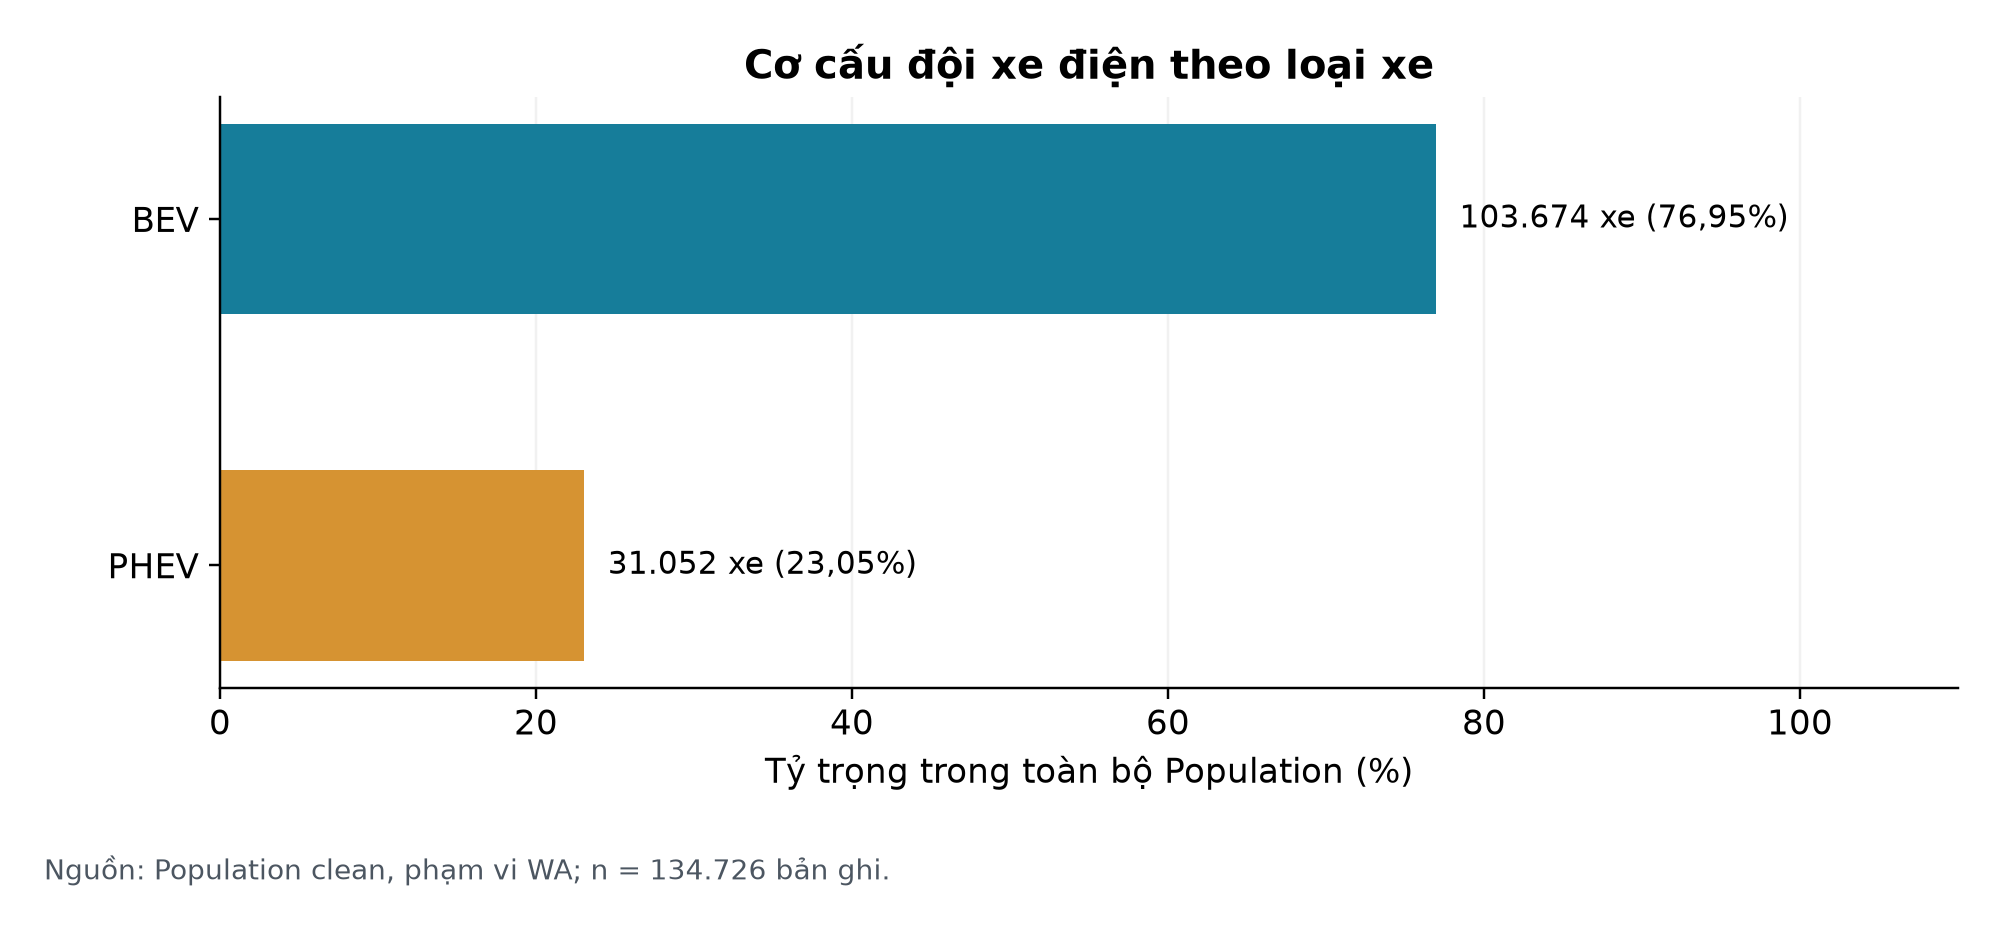

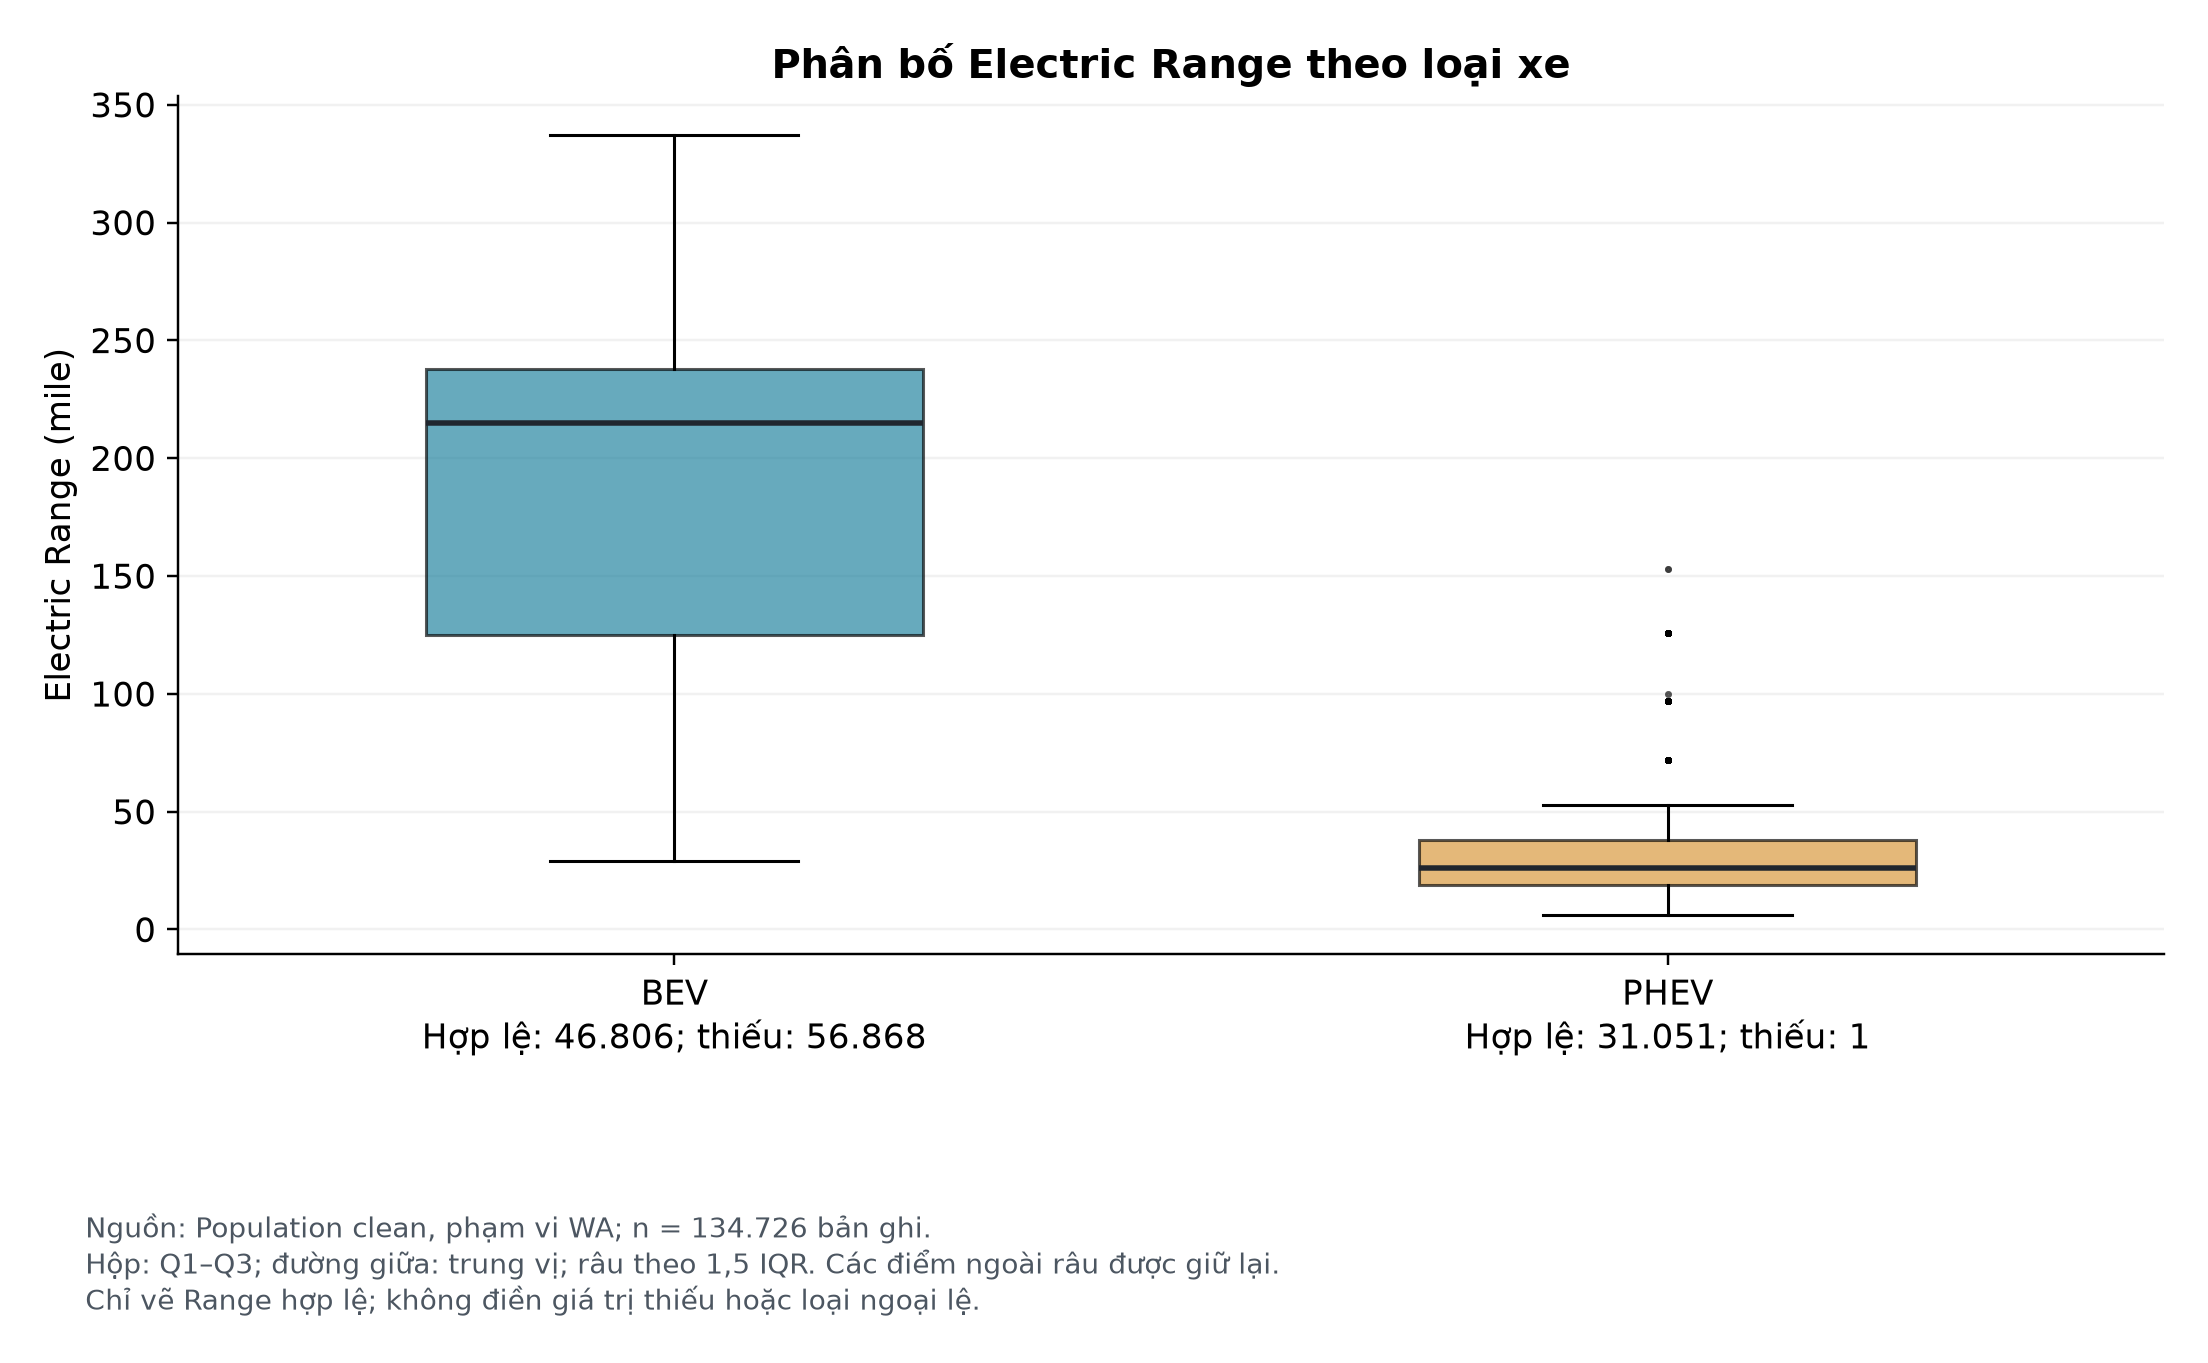

In [4]:
vehicle_tables = vehicle.build_tables(population)
display(vehicle_tables['vehicle_type_frequency.csv'])
display(vehicle_tables['range_summary.csv'])
(OUT/'figures/vehicle').mkdir(parents=True, exist_ok=True)
vehicle.export_figures(population, vehicle_tables, OUT/'figures/vehicle', top_makes=10)
show_png(OUT/'figures/vehicle/vehicle_type_share.png')
show_png(OUT/'figures/vehicle/range_by_vehicle_type.png')


## Địa bàn và mẫu số
County/County–City của Population; tỷ lệ EV của History cùng tháng. Không ghép hai nguồn để tạo mẫu số.

,county,bev,phev,ev_count,share_pct,bev_share_pct,phev_share_pct,rank,cumulative_share_pct,population_n
0,King,56596,14246,70842,52.582278,79.890460,20.109540,1,52.582278,134726
1,Snohomish,12302,2956,15258,11.325208,80.626557,19.373443,2,63.907486,134726
2,Pierce,7687,2723,10410,7.726794,73.842459,26.157541,3,71.634280,134726
3,Clark,5724,2267,7991,5.931298,71.630584,28.369416,4,77.565578,134726
4,Thurston,3455,1396,4851,3.600641,71.222428,28.777572,5,81.166219,134726
5,Kitsap,3227,1234,4461,3.311165,72.338041,27.661959,6,84.477384,134726
6,Spokane,2274,1052,3326,2.468714,68.370415,31.629585,7,86.946098,134726
7,Whatcom,2443,872,3315,2.460550,73.695324,26.304676,8,89.406648,134726
8,Benton,1135,552,1687,1.252171,67.279194,32.720806,9,90.658819,134726
9,Skagit,1105,399,1504,1.116340,73.470745,26.529255,10,91.775158,134726


,date,county,bev,phev,ev_total,non_ev,total_vehicles,ev_pct,ev_share_statewide_pct,rank_ev_count,rank_ev_pct
0,2023-11-30,King,67480,16033,83513,1449408,1532921,5.447965,52.366471,1,1
1,2023-11-30,San Juan,690,188,878,18995,19873,4.418055,0.550546,16,2
2,2023-11-30,Snohomish,15456,3394,18850,626085,644935,2.922775,11.819812,2,3
3,2023-11-30,Jefferson,653,272,925,32648,33573,2.755190,0.580017,14,4
4,2023-11-30,Clark,6962,2554,9516,381700,391216,2.432416,5.966967,4,5
5,2023-11-30,Kitsap,3855,1435,5290,220942,226232,2.338308,3.317072,5,6
6,2023-11-30,Island,1284,467,1751,79728,81479,2.149020,1.097957,11,7
7,2023-11-30,Thurston,3700,1346,5046,235401,240447,2.098591,3.164073,6,8
8,2023-11-30,Whatcom,2908,995,3903,183775,187678,2.079626,2.447360,8,9
9,2023-11-30,Pierce,9206,3068,12274,639133,651407,1.884229,7.696359,3,10


,date,source_rows,counties,ev_total,total_vehicles,statewide_ev_pct,use_groups
0,2023-11-30,78,39,159478,5954054,2.678478,"[Passenger, Truck]"


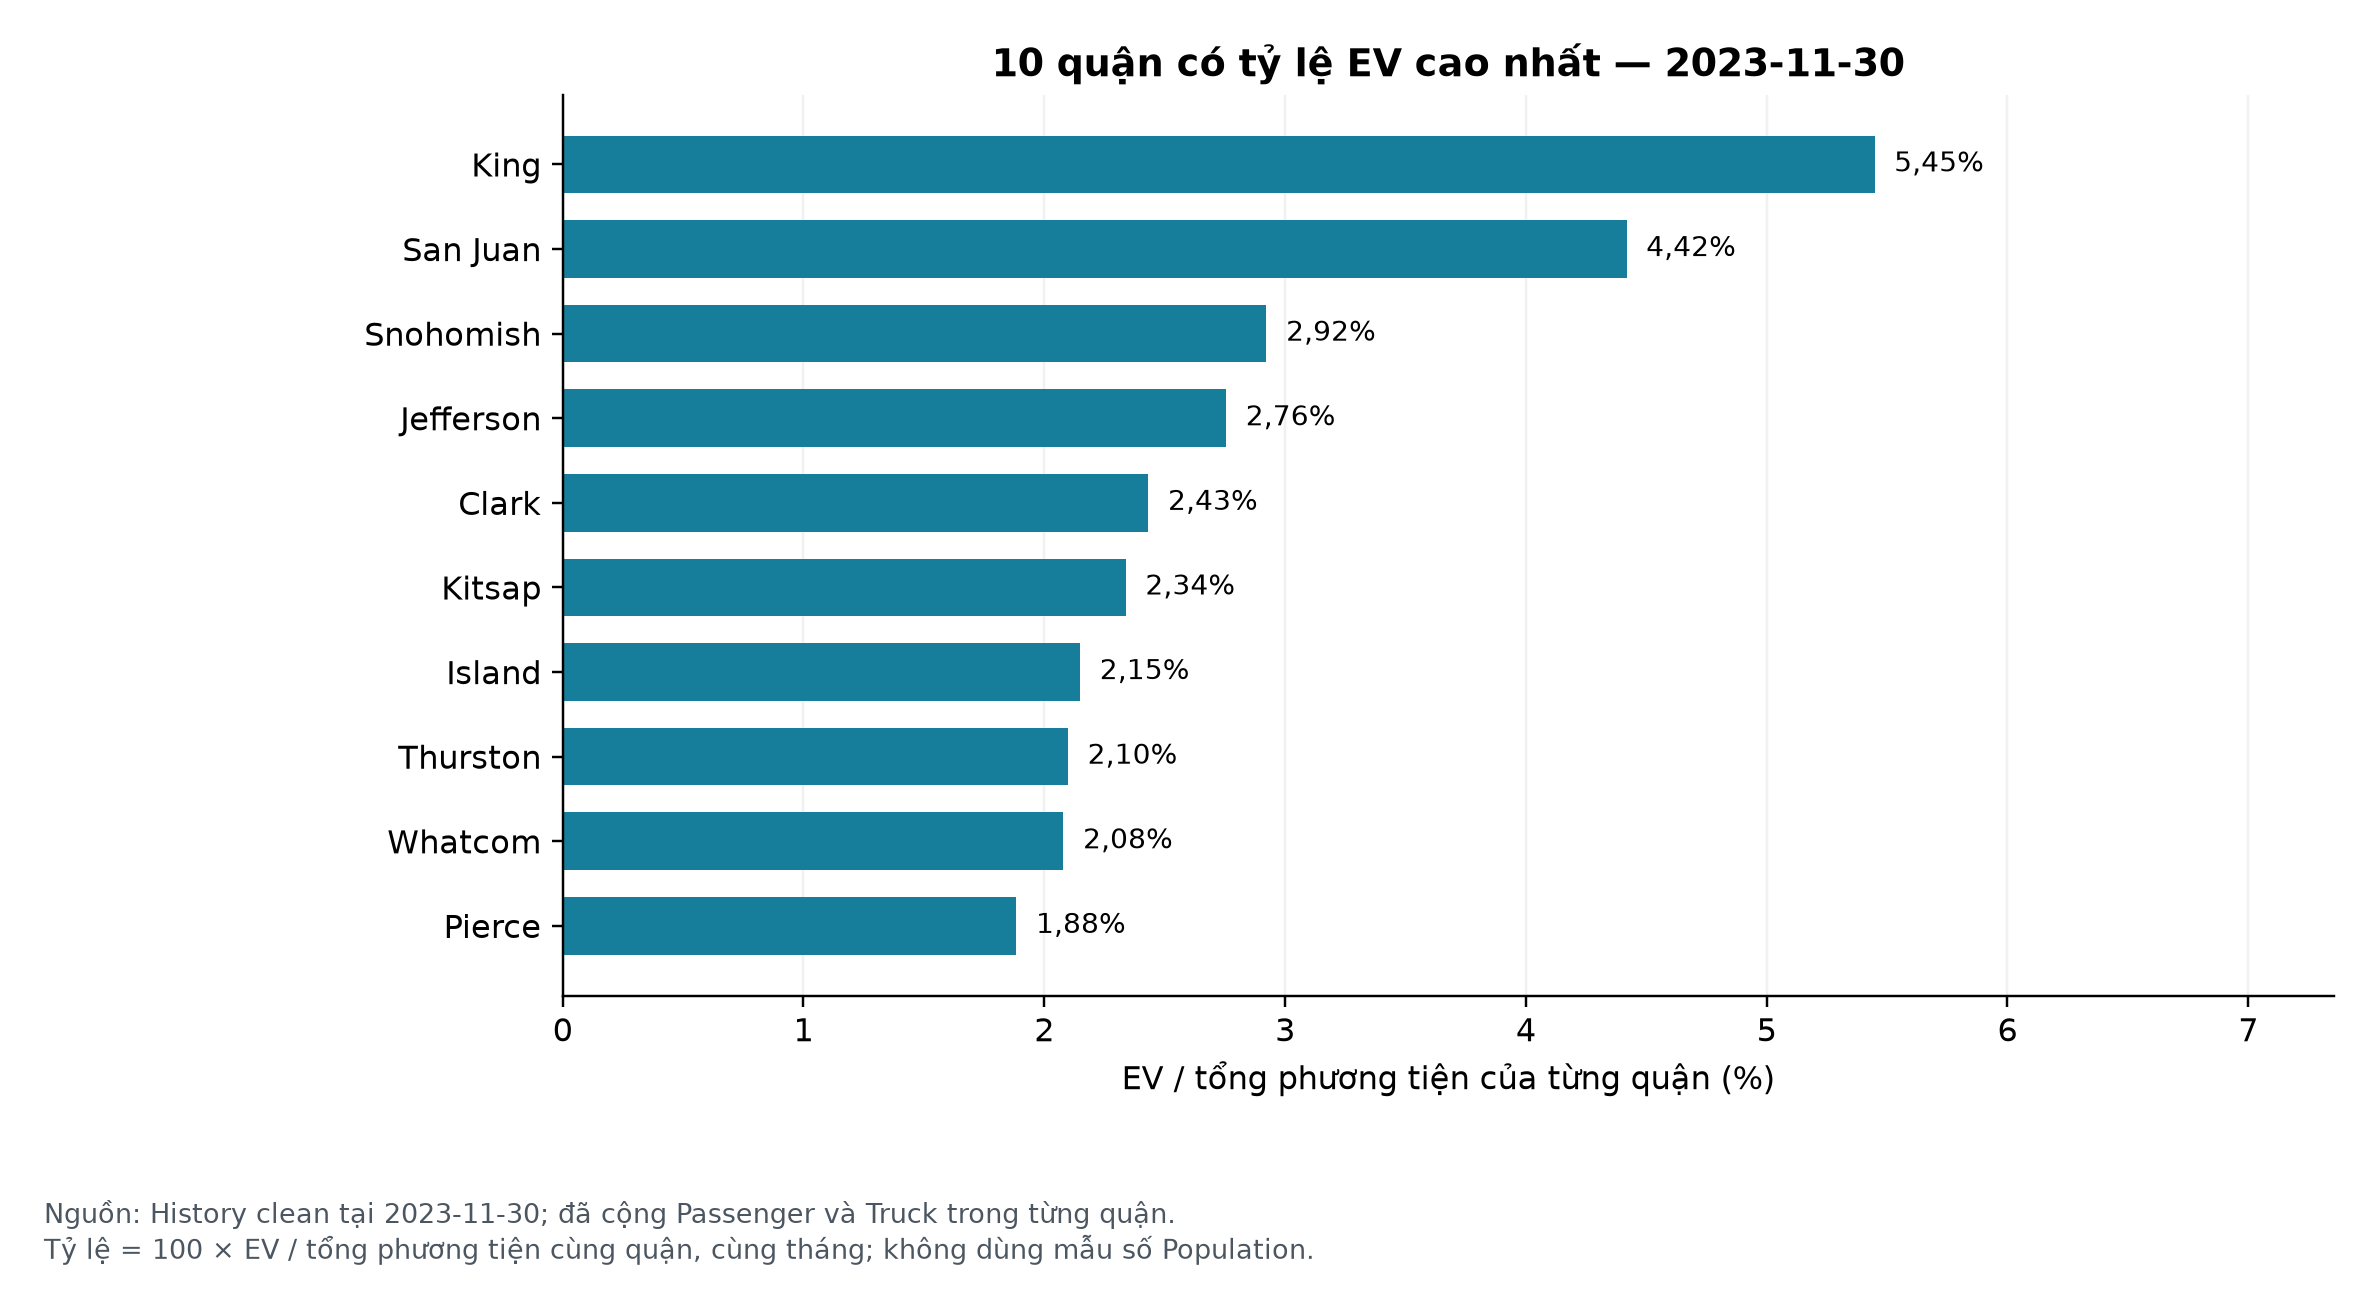

In [5]:
spatial_tables, spatial_summary = spatial.build_tables(population, history)
display(spatial_tables['county_summary.csv'].head(10))
display(spatial_tables['county_ev_rates.csv'].head(10))
display(pd.DataFrame([spatial_summary['history_snapshot']]))
(OUT/'figures/spatial').mkdir(parents=True, exist_ok=True)
spatial.export_figures(spatial_tables, spatial_summary, OUT/'figures/spatial')
show_png(OUT/'figures/spatial/county_ev_rates.png')


## Diễn biến theo tháng
Thay đổi ròng không phải doanh số; YoY thiếu 12 tháng đầu được giữ thiếu.

,series,start_date,end_date,monthly_intervals,start_vehicles,end_vehicles,net_change_vehicles,growth_pct,annualized_growth_pct
0,bev,2017-01-31,2023-11-30,82,14359,124353,109994,766.028275,37.151264
1,phev,2017-01-31,2023-11-30,82,7436,35125,27689,372.364174,25.508944
2,ev_total,2017-01-31,2023-11-30,82,21795,159478,137683,631.718284,33.810241


,date,bev,phev,ev_total,non_ev,total_vehicles,...,ev_mom_growth_pct,ev_yoy_net_change,ev_yoy_growth_pct,ev_log_growth_pct,ev_ma12,net_change_sd12
0,2017-01-31,14359,7436,21795,5918988,5940783,...,NaN,NaN,NaN,NaN,NaN,NaN
1,2017-02-28,14832,7638,22470,5908594,5931064,...,3.097041,NaN,NaN,3.050050,NaN,NaN
2,2017-03-31,15223,7839,23062,5908100,5931162,...,2.634624,NaN,NaN,2.600516,NaN,NaN
3,2017-04-30,15707,8033,23740,5903511,5927251,...,2.939901,NaN,NaN,2.897515,NaN,NaN
4,2017-05-31,16102,8247,24349,5905661,5930010,...,2.565291,NaN,NaN,2.532939,NaN,NaN


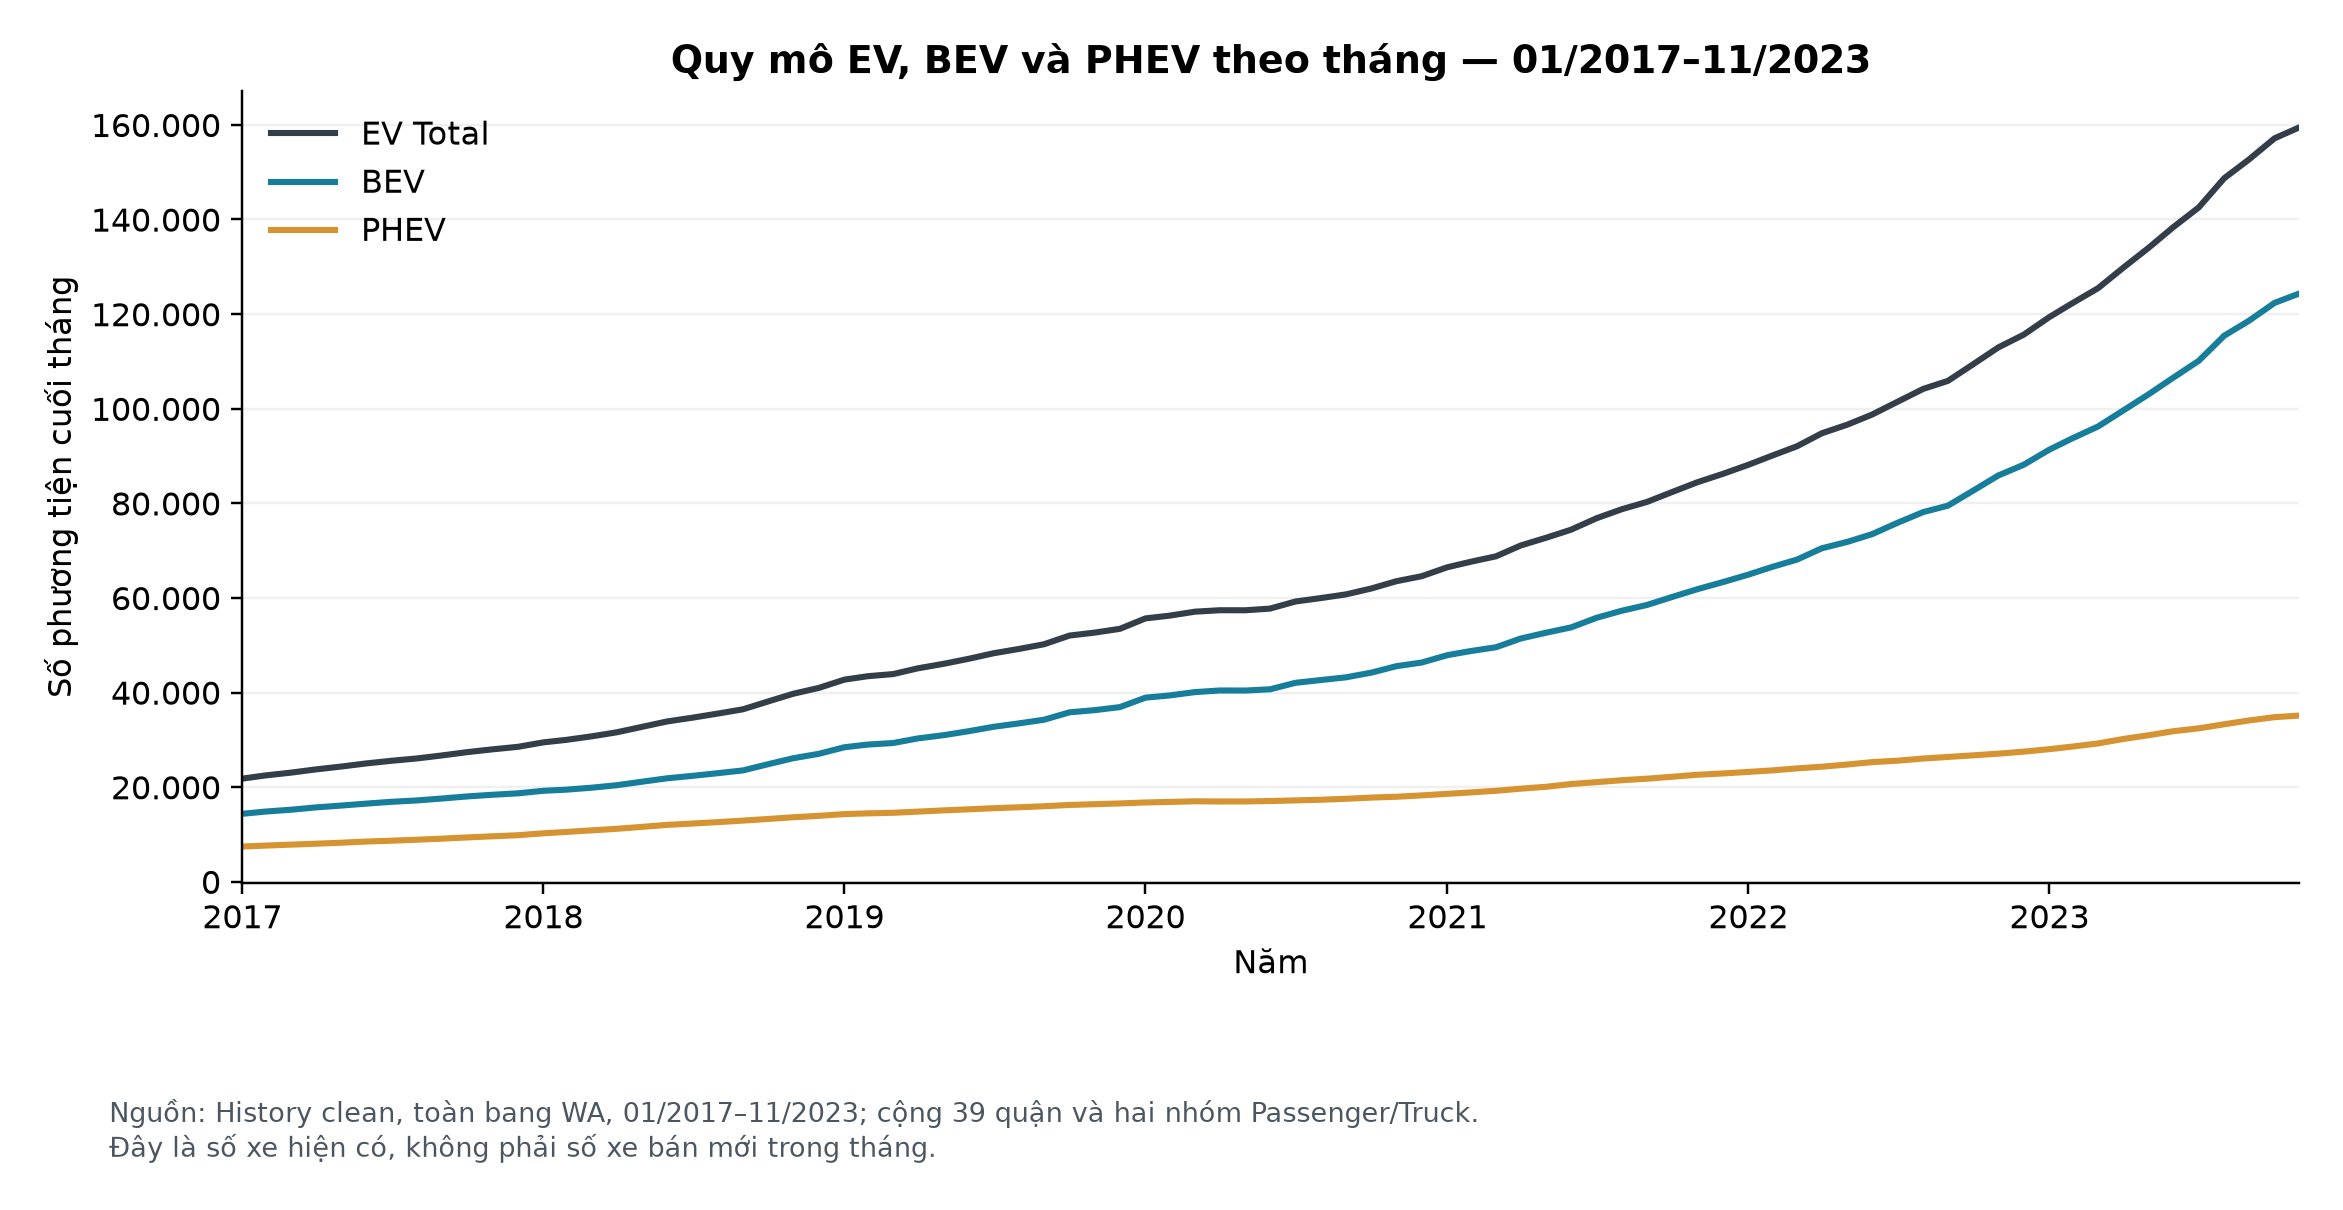

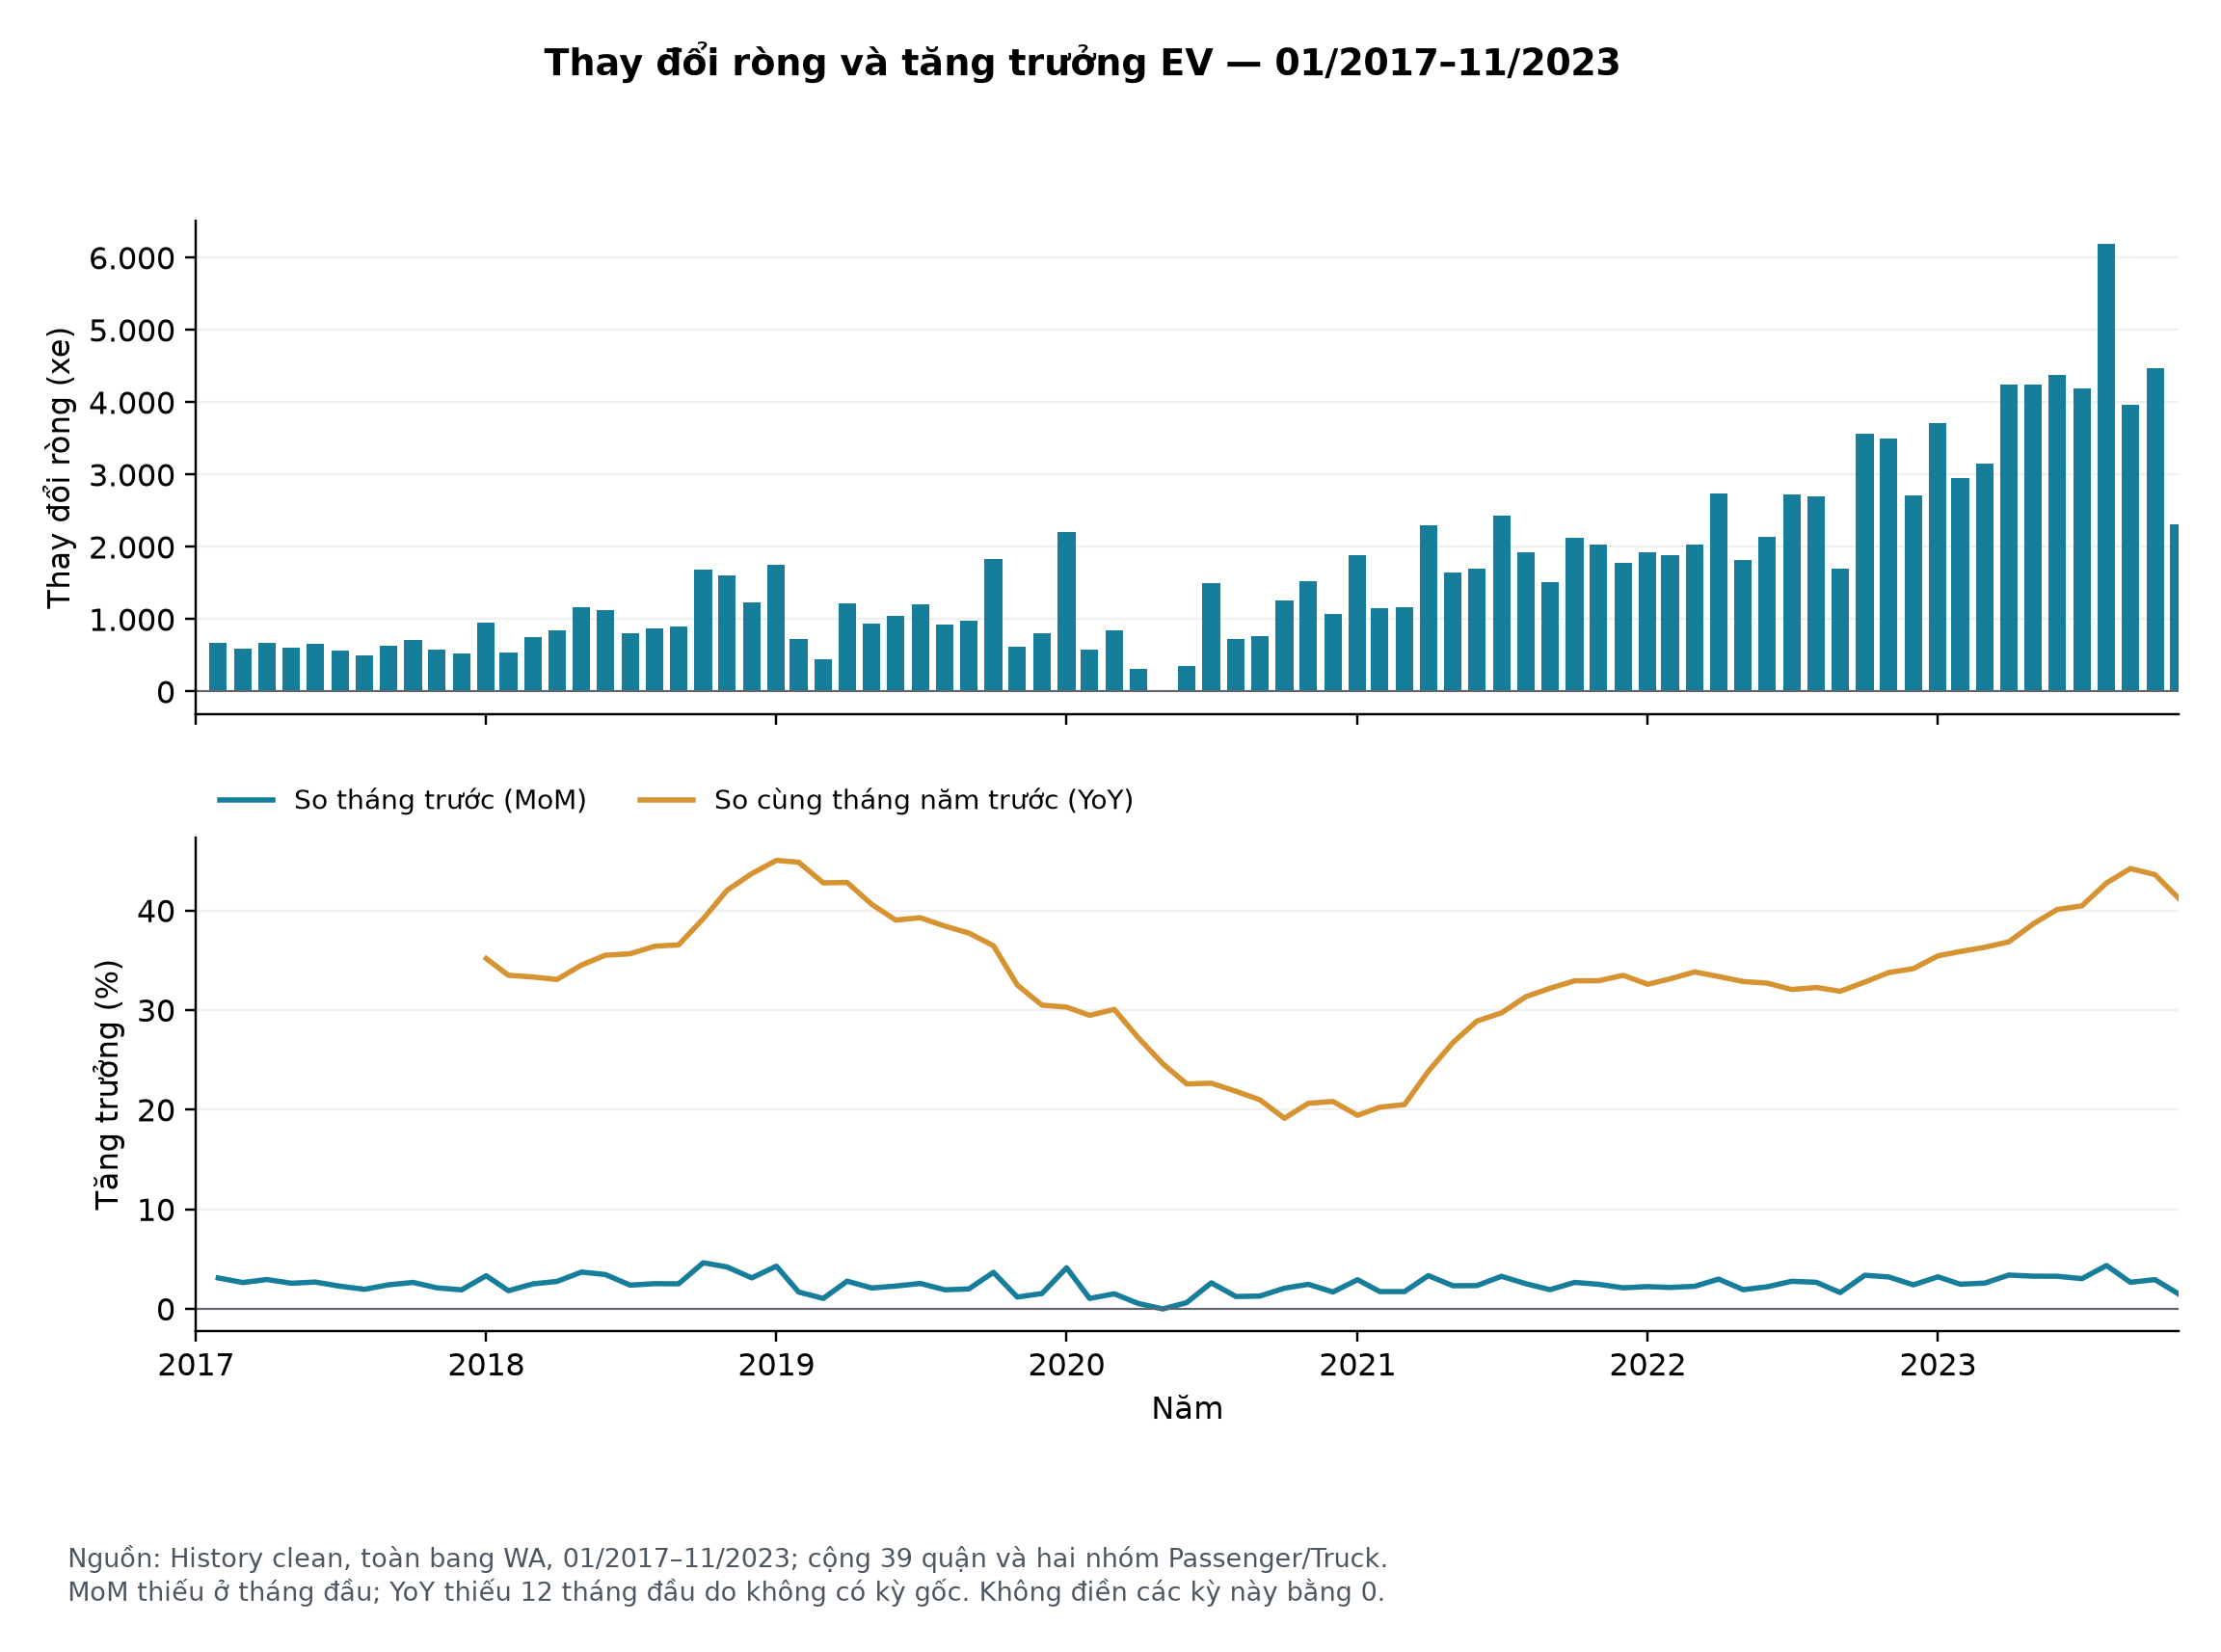

In [6]:
trend_tables = trends.build_tables(history)
display(trend_tables['overall_growth_summary.csv'])
display(trend_tables['monthly_growth.csv'].head())
(OUT/'figures/trends').mkdir(parents=True, exist_ok=True)
trends.export_figures(trend_tables, OUT/'figures/trends')
show_png(OUT/'figures/trends/monthly_ev_population.png')
show_png(OUT/'figures/trends/monthly_ev_growth.png')


## Đối chiếu bảng và xuất demo
Không chỉ đọc lại CSV: bảng vừa được tính bằng các hàm source.

In [7]:

tables = {**vehicle_tables, **spatial_tables, **trend_tables}

for name, frame in tables.items():
    reference = pd.read_csv(
        PROJECT_ROOT / 'results/descriptive' / name
    )
    pd.testing.assert_frame_equal(
        frame, reference, check_dtype=False
    )
    save_table(frame, OUT / 'tables' / name)

save_json(spatial_summary, OUT / 'spatial_summary.json')
print('14 bảng mô tả khớp kết quả đã lưu:', len(tables))


14 bảng mô tả khớp kết quả đã lưu: 14
